In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_excel("your_date_file.xlsx")
df

In [ ]:
# ---------------------------------------------------------------------
# 0. CONFIG
# ---------------------------------------------------------------------

DATA_PATH = '/path/to/your/data' # put data folder here
OUTPUT_DIR = "Figures"
RANDOM_SEED = 42 # fixes jitter positions in raincloud plots so figures are identical on rerun

GROUP_ORDER = ["Control", "PNFA", "Logopenic"]
GROUP_LABELS = {
    "Control": "CN",
    "PNFA": "nfvPPA",
    "Logopenic": "lvPPA"
}
GROUP_COLORS = {
    "Control":     "#4C72B0",
    "PNFA": "#DD8452",
    "Logopenic":  "#55A868",
}

# Speech measures 
MEASURES = ["SWPVI", "SWduration", "WSPVI", "WSduration"]
MEASURE_LABELS = {
    "SWPVI":      "SW PVI",
    "SWduration":  "SW duration(ms)",
    "WSPVI":     "WS PVI",
    "WSduration": "WS duration(ms)",
}

os.makedirs(OUTPUT_DIR, exist_ok=True)


In [ ]:
sub = df[df["SummaryPrimaryDiagnosis"].isin(["PNFA", "Logopenic"])]
long_traj_pts = sub.melt(
    id_vars=["PID", "SummaryPrimaryDiagnosis", "Timepoint ", "DaysMRI"],
    value_vars=MEASURES,
    var_name="measure",
    value_name="value",
).rename(columns={"SummaryPrimaryDiagnosis": "group"})
long_traj_pts

In [ ]:
# should match nunique() above — confirms melt() didn't duplicate/drop anyone
long_traj_pts.groupby("group")["PID"].nunique()
long_traj_pts[long_traj_pts["measure"] == "SWPVI"].groupby("group")["PID"].nunique()

Significance stars used:
  SWPVI: none
  SWduration: [(365, '***'), (730, '***'), (1095, '***')]
  WSPVI: [(365, '*'), (730, '***'), (1095, '***')]
  WSduration: [(0, '***'), (365, '***'), (730, '***'), (1095, '***')]


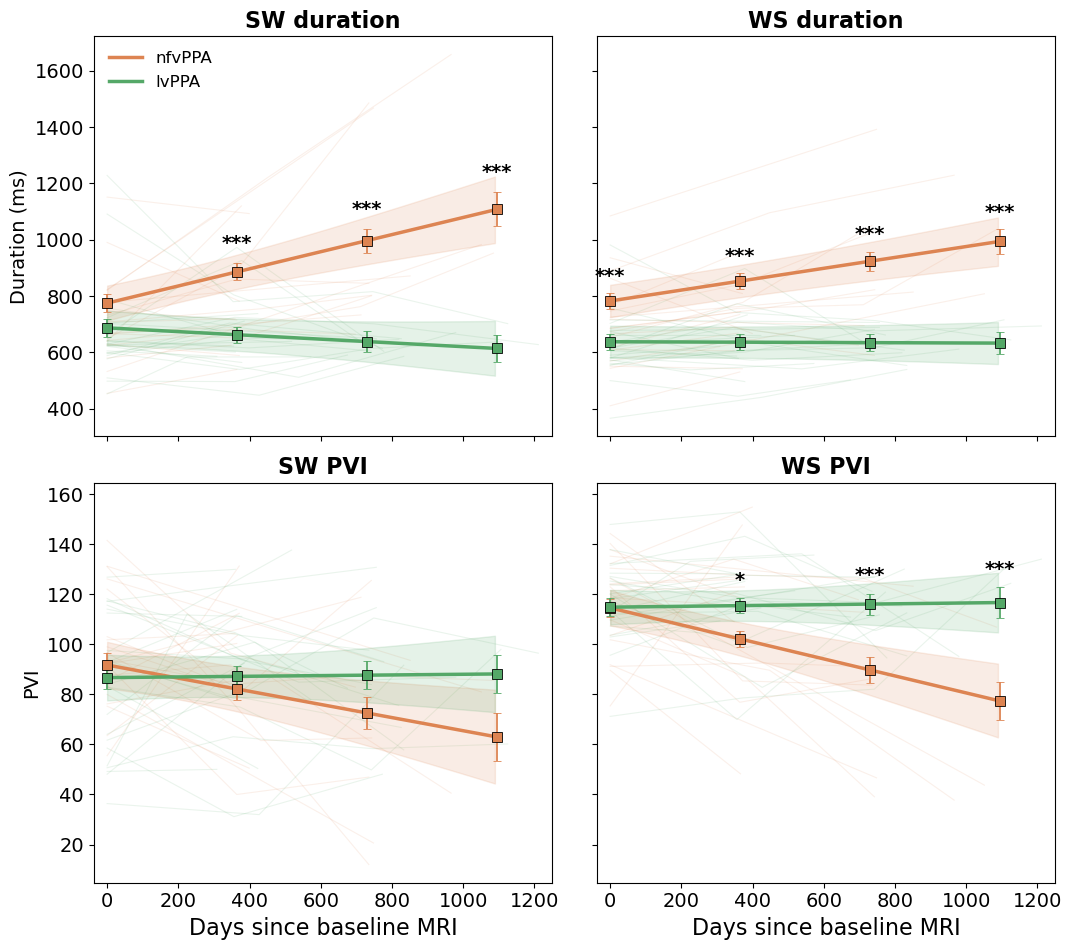

In [ ]:
# ---------------------------------------------------------------------
# EMM trajectory figure using the estimates computed in R (speech_lme.R)
#
# Inputs (written by speech_lme.R to RESULTS_DIR):
#   lme_emmeans.csv          EMMs at the checkpoint days (0, 365, 730)
#   lme_emmeans_smooth.csv   EMMs on a fine grid -> the line and 95% CI band
#   lme_pairwise.csv         PNFA - Logopenic tests -> significance stars
# plus your long-format raw data (long_traj_pts) for the individual lines.
# ---------------------------------------------------------------------

RESULTS_DIR = "/path/to/your/results"
OUTPUT_DIR = RESULTS_DIR

MEASURES = ["SWPVI", "SWduration", "WSPVI", "WSduration"]
MEASURE_LABELS = {"SWPVI": "SW PVI", "SWduration": "SW duration",
                  "WSPVI": "WS PVI", "WSduration": "WS duration"}   # panel titles
GROUP_ORDER = ["PNFA", "Logopenic"]
GROUP_LABELS = {"PNFA": "nfvPPA", "Logopenic": "lvPPA"}
GROUP_COLORS = {"PNFA": "#DD8452", "Logopenic": "#55A868"}

EMM_LINE_MAX = 1095    
X_MAX = 1250          # x-axis limit: shows all observed follow-up (max 1211 days)

# Which p-value decides the stars:
#   "p_sidak_across"         Sidak-corrected across the checkpoint days (recommended)
#   "p_sidak_per_timepoint"  identical to SPSS "Sig." (uncorrected with 2 groups)
P_COLUMN = "p_sidak_across"


# ---- Load the R output ------------------------------------------------
def load_r_emm(path):
    """Read an emmeans CSV from R and rename columns to the names used below."""
    df = pd.read_csv(path)
    return df.rename(columns={"SPSS_Dx": "group", "emmean": "pred", "SE": "se",
                              "lower.CL": "ci_lower", "upper.CL": "ci_upper"})


emm_checkpoints_all = load_r_emm(os.path.join(RESULTS_DIR, "lme_emmeans.csv"))
emm_smooth_all = load_r_emm(os.path.join(RESULTS_DIR, "lme_emmeans_smooth.csv"))
pairwise_all = pd.read_csv(os.path.join(RESULTS_DIR, "lme_pairwise.csv"))

# Checkpoints only up to the EMM range (drops any 3+ year rows from older runs)
emm_checkpoints_all = emm_checkpoints_all[emm_checkpoints_all["DaysMRI"] <= EMM_LINE_MAX]
emm_smooth_all = emm_smooth_all[emm_smooth_all["DaysMRI"] <= EMM_LINE_MAX]


def stars(p):
    if p < .001:
        return "***"
    if p < .01:
        return "**"
    if p < .05:
        return "*"
    return None


def sig_points_from_pairwise(measure):
    """[(day, label)] for every checkpoint where PNFA and Logopenic differ."""
    pw = pairwise_all[(pairwise_all["measure"] == measure) &
                      (pairwise_all["DaysMRI"] <= EMM_LINE_MAX)]
    out = []
    for _, r in pw.iterrows():
        lab = stars(r[P_COLUMN])
        if lab:
            out.append((r["DaysMRI"], lab))
    return out


# ---- Plotting ------------------------------------------------------------
def _add_group_difference_markers(ax, emm_checkpoints, sig_points, offset_frac=0.05):
    """Star above the higher of the two groups (EMM + SE) at each significant day."""
    y_span = emm_checkpoints["ci_upper"].max() - emm_checkpoints["ci_lower"].min()
    offset = y_span * offset_frac
    for day, label in sig_points:
        rows = emm_checkpoints[emm_checkpoints["DaysMRI"] == day]
        if rows.empty:
            continue
        y = (rows["pred"] + rows["se"]).max() + offset
        ax.text(day, y, label, ha="center", va="bottom",
                fontsize=14, fontweight="bold", color="black", zorder=5)


def trajectory_plot_emm(long_df, measure, emm_smooth, emm_checkpoints, ylabel=None,
                        title=None, ax=None, sig_points=None,
                        show_xlabel=True, show_legend=True):
    """Faded individual lines + EMM line and 95% CI band + EMM +/- SE at checkpoints."""
    sub_m = long_df[long_df["measure"] == measure].dropna(subset=["value", "DaysMRI"])
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(6, 5))

    for g in GROUP_ORDER:
        color = GROUP_COLORS[g]

        for _, patient_data in sub_m[sub_m["group"] == g].groupby("PID"):
            patient_data = patient_data.sort_values("DaysMRI")
            ax.plot(patient_data["DaysMRI"], patient_data["value"],
                    color=color, alpha=0.12, linewidth=0.8, zorder=1)

        emm_g = emm_smooth[emm_smooth["group"] == g].sort_values("DaysMRI")
        ax.plot(emm_g["DaysMRI"], emm_g["pred"], color=color, linewidth=2.5,
                zorder=3, label=GROUP_LABELS.get(g, g))
        ax.fill_between(emm_g["DaysMRI"], emm_g["ci_lower"], emm_g["ci_upper"],
                        color=color, alpha=0.15, zorder=2)

        chk_g = emm_checkpoints[emm_checkpoints["group"] == g].sort_values("DaysMRI")
        ax.errorbar(chk_g["DaysMRI"], chk_g["pred"], yerr=chk_g["se"],
                    fmt="s", color=color, markersize=7, markeredgecolor="black",
                    markeredgewidth=0.6, capsize=3, elinewidth=1.3, zorder=4)

    if sig_points:
        _add_group_difference_markers(ax, emm_checkpoints, sig_points)

    ax.set_xlim(-X_MAX * 0.03, X_MAX)
    if show_xlabel:
        ax.set_xlabel("Days since baseline MRI", fontsize=16)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=14)
    if title:
        ax.set_title(title, fontsize=16, fontweight="bold")
    if show_legend:
        ax.legend(frameon=False, fontsize=12, loc="upper left")
    ax.tick_params(axis="both", labelsize=14)
    if own_fig:
        fig.tight_layout()
        return fig, ax
    return ax


LAYOUT = [
    ["SWduration", "WSduration"],   # row 0 -> share a y-axis
    ["SWPVI",      "WSPVI"],        # row 1 -> share a y-axis
]
ROW_YLABELS = ["Duration (ms)", "PVI"]   # one y-axis label per row


def plot_all_measures_emm(long_df, auto_sig=True, sig_points_dict=None):
    """2x2 grid in LAYOUT order; y-axis shared within each row, x-axis shared.
    auto_sig=True: stars from lme_pairwise.csv. Otherwise pass
    sig_points_dict = {measure: [(day, "*"), ...]}."""
    sig_points_dict = sig_points_dict or {}
    n_rows, n_cols = len(LAYOUT), len(LAYOUT[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.8 * n_rows),
                             sharex=True, sharey="row", squeeze=False)

    for r, row in enumerate(LAYOUT):
        for c, measure in enumerate(row):
            emm_smooth = emm_smooth_all[emm_smooth_all["measure"] == measure]
            emm_checkpoints = emm_checkpoints_all[emm_checkpoints_all["measure"] == measure]
            sig = sig_points_from_pairwise(measure) if auto_sig else sig_points_dict.get(measure)
            trajectory_plot_emm(long_df, measure, emm_smooth, emm_checkpoints,
                                ylabel=ROW_YLABELS[r] if c == 0 else None,
                                title=MEASURE_LABELS.get(measure, measure),
                                ax=axes[r, c], sig_points=sig,
                                show_xlabel=(r == n_rows - 1),
                                show_legend=(r == 0 and c == 0))
    fig.tight_layout()
    return fig, axes


# --- Run it ---
# long_traj_pts: long-format raw data, columns PID, group, DaysMRI, measure, value
fig, axes = plot_all_measures_emm(long_traj_pts, auto_sig=True)
for ext in ("pdf", "png", "svg"):
    fig.savefig(os.path.join(OUTPUT_DIR, f"trajectory_emm_R.{ext}"), bbox_inches="tight", dpi=300)

print("Significance stars used:")
for m in MEASURES:
    print(f"  {m}: {sig_points_from_pairwise(m) or 'none'}")